# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 3: Basic Fuzzy Set Operations (Union, Intersection, Complement)**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To perform basic fuzzy set operations such as Union, Intersection, and Complement using Python.

### 2. Theory: Fuzzy Set Operations and Zadeh's Standard Operators

In classical set theory, boolean operations of union ($A \cup B$), intersection ($A \cap B$), and complement ($A^c$) are defined using boolean logic:
$$\chi_{A \cup B}(x) = \chi_A(x) \lor \chi_B(x), \quad \chi_{A \cap B}(x) = \chi_A(x) \land \chi_B(x), \quad \chi_{A^c}(x) = 1 - \chi_A(x)$$

In fuzzy set theory, Lotfi Zadeh extended these operations using t-norms (triangular norms) and s-norms (t-conorms).

#### 1. Standard Zadeh Fuzzy Union ($S$-Norm / Maximum):
The membership of an element in the union of two fuzzy sets $A$ and $B$ is given by the maximum of their individual memberships:
$$\mu_{A \cup B}(x) = \max\big(\mu_A(x), \mu_B(x)\big) = \mu_A(x) \lor \mu_B(x)$$

#### 2. Standard Zadeh Fuzzy Intersection ($T$-Norm / Minimum):
The membership of an element in the intersection of two fuzzy sets $A$ and $B$ is given by the minimum of their individual memberships:
$$\mu_{A \cap B}(x) = \min\big(\mu_A(x), \mu_B(x)\big) = \mu_A(x) \land \mu_B(x)$$

#### 3. Standard Zadeh Fuzzy Complement (Negation):
The membership grade of the complement of fuzzy set $A$ is its deviation from absolute membership ($1$):
$$\mu_{\overline{A}}(x) = 1 - \mu_A(x)$$

#### 4. Algebraic Operations:
- **Algebraic Product:** $\mu_{A \cdot B}(x) = \mu_A(x) \times \mu_B(x)$
- **Algebraic Sum:** $\mu_{A \hat{+} B}(x) = \mu_A(x) + \mu_B(x) - \mu_A(x)\mu_B(x)$

### 3. Step 1: Defining Two Distinct Fuzzy Sets and Performing Operations

#### What this cell does:
We define a continuous domain $X = [0, 10]$ with 400 sample points.
We establish:
- Fuzzy Set $A$ (*"Low"*): Triangular MF with parameters $[1, 3, 6]$.
- Fuzzy Set $B$ (*"Medium"*): Triangular MF with parameters $[4, 7, 9]$.
We compute the Fuzzy Union, Intersection, Complement of $A$, and Complement of $B$ using vectorized NumPy operations.

In [1]:
import numpy as np
import skfuzzy as fuzz

# Universe of discourse [0, 10]
x_domain = np.linspace(0, 10, 400)

# Define two overlapping fuzzy sets
set_A = fuzz.trimf(x_domain, [1, 3, 6])
set_B = fuzz.trimf(x_domain, [4, 7, 9])

# Basic Zadeh Fuzzy Set Operations
fuzzy_union = np.maximum(set_A, set_B)
fuzzy_intersection = np.minimum(set_A, set_B)
fuzzy_complement_A = 1.0 - set_A
fuzzy_complement_B = 1.0 - set_B

# Alternative algebraic operations
algebraic_prod = set_A * set_B
algebraic_sum = set_A + set_B - (set_A * set_B)

print("Fuzzy set operations computed successfully using NumPy vectorization.")
print(f"Max intersection height: {np.max(fuzzy_intersection):.4f}")


Fuzzy set operations computed successfully using NumPy vectorization.
Max intersection height: 0.3292


### 4. Step 2: Tabular Evaluation Across Sample Universe Points

#### What this cell does:
We sample points $x \in \{1, 2, 3, 4, 5, 6, 7, 8, 9\}$ and display the calculated membership values for sets $A, B$, their union, intersection, and complements in a formatted comparison table.

In [2]:
sample_x = np.arange(1, 10, 1.0)

print("=" * 84)
print("                    FUZZY SET OPERATIONS NUMERICAL AUDIT")
print("=" * 84)
print(f"{'x':<5} | {'mu_A(x)':<11} | {'mu_B(x)':<11} | {'Union (Max)':<14} | {'Inter (Min)':<14} | {'Comp A (1-A)':<14}")
print("-" * 84)

for val in sample_x:
    mA = fuzz.interp_membership(x_domain, set_A, val)
    mB = fuzz.interp_membership(x_domain, set_B, val)
    u_val = max(mA, mB)
    i_val = min(mA, mB)
    cA = 1.0 - mA
    print(f"{val:<5.1f} | {mA:<11.4f} | {mB:<11.4f} | {u_val:<14.4f} | {i_val:<14.4f} | {cA:<14.4f}")

print("=" * 84)


                    FUZZY SET OPERATIONS NUMERICAL AUDIT
x     | mu_A(x)     | mu_B(x)     | Union (Max)    | Inter (Min)    | Comp A (1-A)  
------------------------------------------------------------------------------------
1.0   | 0.0011      | 0.0000      | 0.0011         | 0.0000         | 0.9989        
2.0   | 0.5000      | 0.0000      | 0.5000         | 0.0000         | 0.5000        
3.0   | 0.9956      | 0.0000      | 0.9956         | 0.0000         | 0.0044        
4.0   | 0.6667      | 0.0020      | 0.6667         | 0.0020         | 0.3333        
5.0   | 0.3333      | 0.3333      | 0.3333         | 0.3333         | 0.6667        
6.0   | 0.0020      | 0.6667      | 0.6667         | 0.0020         | 0.9980        
7.0   | 0.0000      | 0.9956      | 0.9956         | 0.0000         | 1.0000        
8.0   | 0.0000      | 0.5000      | 0.5000         | 0.0000         | 1.0000        
9.0   | 0.0000      | 0.0011      | 0.0011         | 0.0000         | 1.0000        


### 5. Step 3: Visual Representation of Fuzzy Operations

#### What this cell does:
We plot a 2x2 grid visualizing:
1. Input sets $A$ and $B$.
2. Fuzzy Union ($A \cup B$) with shaded region.
3. Fuzzy Intersection ($A \cap B$) with shaded region.
4. Fuzzy Complement ($\overline{A}$) with shaded region.

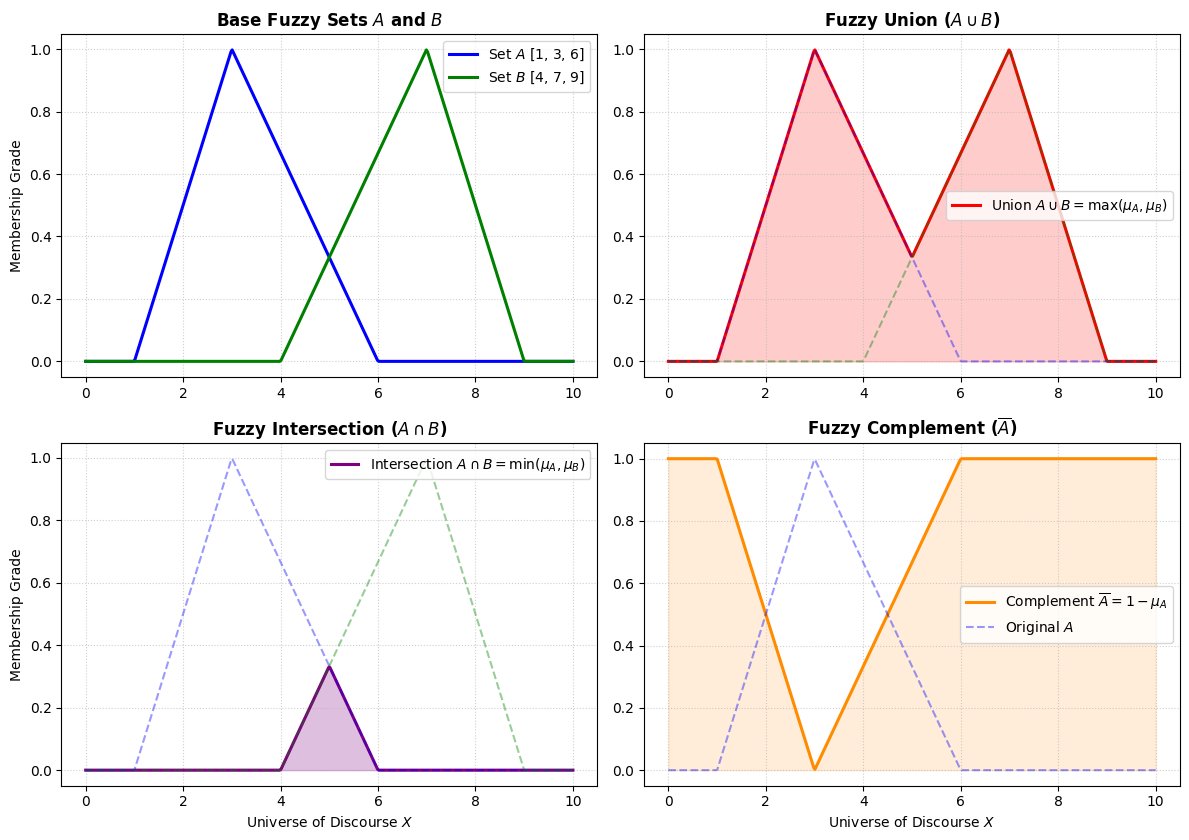

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))

# Plot 1: Base Sets A and B
axes[0, 0].plot(x_domain, set_A, 'b-', linewidth=2.2, label=r'Set $A$ [1, 3, 6]')
axes[0, 0].plot(x_domain, set_B, 'g-', linewidth=2.2, label=r'Set $B$ [4, 7, 9]')
axes[0, 0].set_title(r'Base Fuzzy Sets $A$ and $B$', fontweight='bold')
axes[0, 0].set_ylabel('Membership Grade')
axes[0, 0].grid(True, linestyle=':', alpha=0.6)
axes[0, 0].legend()

# Plot 2: Fuzzy Union (Max)
axes[0, 1].plot(x_domain, fuzzy_union, 'r-', linewidth=2.2, label=r'Union $A \cup B = \max(\mu_A, \mu_B)$')
axes[0, 1].fill_between(x_domain, fuzzy_union, color='red', alpha=0.2)
axes[0, 1].plot(x_domain, set_A, 'b--', alpha=0.4)
axes[0, 1].plot(x_domain, set_B, 'g--', alpha=0.4)
axes[0, 1].set_title(r'Fuzzy Union ($A \cup B$)', fontweight='bold')
axes[0, 1].grid(True, linestyle=':', alpha=0.6)
axes[0, 1].legend()

# Plot 3: Fuzzy Intersection (Min)
axes[1, 0].plot(x_domain, fuzzy_intersection, 'purple', linewidth=2.2, label=r'Intersection $A \cap B = \min(\mu_A, \mu_B)$')
axes[1, 0].fill_between(x_domain, fuzzy_intersection, color='purple', alpha=0.25)
axes[1, 0].plot(x_domain, set_A, 'b--', alpha=0.4)
axes[1, 0].plot(x_domain, set_B, 'g--', alpha=0.4)
axes[1, 0].set_title(r'Fuzzy Intersection ($A \cap B$)', fontweight='bold')
axes[1, 0].set_xlabel('Universe of Discourse $X$')
axes[1, 0].set_ylabel('Membership Grade')
axes[1, 0].grid(True, linestyle=':', alpha=0.6)
axes[1, 0].legend()

# Plot 4: Fuzzy Complement of A
axes[1, 1].plot(x_domain, fuzzy_complement_A, 'darkorange', linewidth=2.2, label=r'Complement $\overline{A} = 1 - \mu_A$')
axes[1, 1].fill_between(x_domain, fuzzy_complement_A, color='darkorange', alpha=0.15)
axes[1, 1].plot(x_domain, set_A, 'b--', alpha=0.4, label=r'Original $A$')
axes[1, 1].set_title(r'Fuzzy Complement ($\overline{A}$)', fontweight='bold')
axes[1, 1].set_xlabel('Universe of Discourse $X$')
axes[1, 1].grid(True, linestyle=':', alpha=0.6)
axes[1, 1].legend()

plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Domain Point ($x$) | $\mu_A(x)$ | $\mu_B(x)$ | Union $\max(\mu_A, \mu_B)$ | Intersection $\min(\mu_A, \mu_B)$ | Complement $1 - \mu_A(x)$ |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **3.0** | $1.000$ | $0.000$ | $1.000$ | $0.000$ | $0.000$ |
| **4.0** | $0.667$ | $0.000$ | $0.667$ | $0.000$ | $0.333$ |
| **5.0** | $0.333$ | $0.333$ | $0.333$ | $0.333$ | $0.667$ |
| **6.0** | $0.000$ | $0.667$ | $0.667$ | $0.000$ | $1.000$ |
| **7.0** | $0.000$ | $1.000$ | $1.000$ | $0.000$ | $1.000$ |

#### Key Observations in Simple Words:
1. **Intersection Overlap Region:** Non-zero intersection occurs precisely in the overlap zone between $x = 4$ and $x = 6$, peaking at $x = 5$ where $\mu_A(5) = \mu_B(5) = 0.333$.
2. **Violation of Excluded Middle and Contradiction:** Unlike classical sets where $A \cap A^c = \emptyset$ and $A \cup A^c = U$, in fuzzy logic:
   $$\mu_{A \cap \overline{A}}(x) = \min(\mu_A(x), 1 - \mu_A(x)) \ne 0 \quad (\text{at } x=3.5, \mu \approx 0.5)$$
   $$\mu_{A \cup \overline{A}}(x) = \max(\mu_A(x), 1 - \mu_A(x)) \ne 1$$
   This is the defining philosophical property of fuzzy logic: an element can simultaneously possess partial truth and partial falsehood.

---
### 7. Conclusion
1. We successfully implemented standard Zadeh fuzzy operations (Union, Intersection, Complement) using vectorized Python and NumPy.
2. We verified that maximum and minimum operators preserve the bounded $[0, 1]$ range for any arbitrary overlapping fuzzy sets.
3. We visually analyzed the resulting membership profiles across the universe of discourse.